In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]



path = '../../DESRES_NATIVE_DATA/BPTI/'

In [102]:
# RMS deviation of native backbone H...O hydrogen-bond distances
# for BPTI residues 2-7
# native H-bonds are detected using Baker-Hubbard geometry
# and then remapped onto protein.pdb by resSeq + atom name
'''
import mdtraj as md
import numpy as np

path = '../../DESRES_NATIVE_DATA/BPTI/'

native_file = path + 'native_structure_5PTI/native_amber.pdb'
topology_file = path + 'protein.pdb'

traj_names = np.sort(find_xtc_filenames(path))

# ------------------------------------------------------------------
# Load native reference and trajectory topology
# ------------------------------------------------------------------

native = md.load(native_file)
traj_top = md.load_topology(topology_file)

residue_range = set(range(2, 8))

print("Residues of interest:", sorted(residue_range))
print("Native hydrogen atoms:", len(native.topology.select("element H")))

# ------------------------------------------------------------------
# Detect native H-bonds using Baker-Hubbard
#
# MDTraj Baker-Hubbard criterion:
# donor-acceptor distance < 0.25 nm
# H-donor-acceptor angle < 2*pi/3
#
# returned columns:
# donor heavy atom, donor H, acceptor heavy atom
# ------------------------------------------------------------------

hbonds_native = md.baker_hubbard(native, periodic=False)

pair_defs = []

for donor_idx, hydrogen_idx, acceptor_idx in hbonds_native:

    donor_atom = native.topology.atom(donor_idx)
    hydrogen_atom = native.topology.atom(hydrogen_idx)
    acceptor_atom = native.topology.atom(acceptor_idx)

    donor_res = donor_atom.residue
    acceptor_res = acceptor_atom.residue

    # both residues must be within residues 2-7
    if donor_res.resSeq not in residue_range:
        continue

    if acceptor_res.resSeq not in residue_range:
        continue

    # backbone H-bonds only
    if donor_atom.name != "N":
        continue

    if acceptor_atom.name not in ("O", "OXT"):
        continue

    pair_defs.append((
        donor_res.resSeq,
        donor_atom.name,
        hydrogen_atom.name,
        acceptor_res.resSeq,
        acceptor_atom.name,
        donor_idx,
        hydrogen_idx,
        acceptor_idx
    ))

print(f"\nSelected {len(pair_defs)} native backbone hydrogen bonds:")

for donor_resseq, donor_name, hydrogen_name, acceptor_resseq, acceptor_name, donor_idx, hydrogen_idx, acceptor_idx in pair_defs:

    ho_dist = md.compute_distances(
        native,
        np.array([[hydrogen_idx, acceptor_idx]], dtype=int),
        periodic=False
    )[0,0]

    dha_angle = md.compute_angles(
        native,
        np.array([[donor_idx, hydrogen_idx, acceptor_idx]], dtype=int),
        periodic=False
    )[0,0]

    print(
        f"{donor_resseq}:{donor_name}-{hydrogen_name} -> "
        f"{acceptor_resseq}:{acceptor_name}   "
        f"H...O = {ho_dist:.3f} nm   "
        f"D-H...A = {np.degrees(dha_angle):.1f} deg"
    )

assert len(pair_defs) > 0, "No native backbone hydrogen bonds found within residues 2-7."

# ------------------------------------------------------------------
# Remap native H-bond atoms onto trajectory topology
# using residue number + atom name
# ------------------------------------------------------------------

traj_ho_pairs = []
native_ho_distances = []

for donor_resseq, donor_name, hydrogen_name, acceptor_resseq, acceptor_name, donor_idx, hydrogen_idx, acceptor_idx in pair_defs:

    hydrogen_matches = [
        atom.index for atom in traj_top.atoms
        if atom.residue.resSeq == donor_resseq and atom.name == hydrogen_name
    ]

    acceptor_matches = [
        atom.index for atom in traj_top.atoms
        if atom.residue.resSeq == acceptor_resseq and atom.name == acceptor_name
    ]

    if len(hydrogen_matches) != 1:
        raise ValueError(
            f"Could not uniquely map donor H "
            f"{donor_resseq}:{hydrogen_name} onto protein.pdb; "
            f"found {len(hydrogen_matches)} matches"
        )

    if len(acceptor_matches) != 1:
        raise ValueError(
            f"Could not uniquely map acceptor "
            f"{acceptor_resseq}:{acceptor_name} onto protein.pdb; "
            f"found {len(acceptor_matches)} matches"
        )

    traj_ho_pairs.append(
        (hydrogen_matches[0], acceptor_matches[0])
    )

    native_ho_distance = md.compute_distances(
        native,
        np.array([[hydrogen_idx, acceptor_idx]], dtype=int),
        periodic=False
    )[0,0]

    native_ho_distances.append(native_ho_distance)

traj_ho_pairs = np.asarray(traj_ho_pairs, dtype=int)
native_ho_distances = np.asarray(native_ho_distances, dtype=float)

print("\nMapped trajectory H...O pairs:")

for pair_def, pair in zip(pair_defs, traj_ho_pairs):

    donor_resseq, donor_name, hydrogen_name, acceptor_resseq, acceptor_name, *_ = pair_def
    hydrogen_idx, acceptor_idx = pair

    print(
        f"{donor_resseq}:{hydrogen_name} -> "
        f"{acceptor_resseq}:{acceptor_name}   "
        f"indices {hydrogen_idx} -> {acceptor_idx}"
    )

# ------------------------------------------------------------------
# Calculate RMS deviation from native H...O distances
# ------------------------------------------------------------------

hbond_distance_rmsd_all = []

for traj in traj_names:

    print(traj)

    u = md.load(path + traj, top=topology_file)

    distances = md.compute_distances(
        u,
        traj_ho_pairs,
        periodic=False
    )

    hbond_distance_rmsd = np.sqrt(
        np.mean(
            (distances - native_ho_distances[None,:])**2,
            axis=1
        )
    )

    hbond_distance_rmsd_all.append(hbond_distance_rmsd)

# ------------------------------------------------------------------
# Concatenate and save
# ------------------------------------------------------------------

hbond_distance_rmsd_all = np.concatenate(hbond_distance_rmsd_all)

print("\nTotal frames:", len(hbond_distance_rmsd_all))
print("Mean H-bond distance RMSD:", np.mean(hbond_distance_rmsd_all), "nm")
print("Min H-bond distance RMSD:", np.min(hbond_distance_rmsd_all), "nm")
print("Max H-bond distance RMSD:", np.max(hbond_distance_rmsd_all), "nm")

np.save(
    path + 'hbond_distance_rmsd_res2_7_all_trajs.npy',
    hbond_distance_rmsd_all
)
'''

'\nimport mdtraj as md\nimport numpy as np\n\npath = \'../../DESRES_NATIVE_DATA/BPTI/\'\n\nnative_file = path + \'native_structure_5PTI/native_amber.pdb\'\ntopology_file = path + \'protein.pdb\'\n\ntraj_names = np.sort(find_xtc_filenames(path))\n\n# ------------------------------------------------------------------\n# Load native reference and trajectory topology\n# ------------------------------------------------------------------\n\nnative = md.load(native_file)\ntraj_top = md.load_topology(topology_file)\n\nresidue_range = set(range(2, 8))\n\nprint("Residues of interest:", sorted(residue_range))\nprint("Native hydrogen atoms:", len(native.topology.select("element H")))\n\n# ------------------------------------------------------------------\n# Detect native H-bonds using Baker-Hubbard\n#\n# MDTraj Baker-Hubbard criterion:\n# donor-acceptor distance < 0.25 nm\n# H-donor-acceptor angle < 2*pi/3\n#\n# returned columns:\n# donor heavy atom, donor H, acceptor heavy atom\n# ---------------

In [88]:
# RMS deviation of native backbone H...O hydrogen-bond distances
# for BPTI residues 47-56
# native H-bonds are detected using Baker-Hubbard geometry
# and then remapped onto protein.pdb by resSeq + atom name
'''
import mdtraj as md
import numpy as np

path = '../../DESRES_NATIVE_DATA/BPTI/'

native_file = path + 'native_structure_5PTI/native_amber.pdb'
topology_file = path + 'protein.pdb'

traj_names = np.sort(find_xtc_filenames(path))

# ------------------------------------------------------------------
# Load native reference and trajectory topology
# ------------------------------------------------------------------

native = md.load(native_file)
traj_top = md.load_topology(topology_file)

residue_range = set(range(47, 57))

print("Residues of interest:", sorted(residue_range))
print("Native hydrogen atoms:", len(native.topology.select("element H")))

# ------------------------------------------------------------------
# Detect native H-bonds using Baker-Hubbard
# ------------------------------------------------------------------

hbonds_native = md.baker_hubbard(native, periodic=False)

pair_defs = []

for donor_idx, hydrogen_idx, acceptor_idx in hbonds_native:

    donor_atom = native.topology.atom(donor_idx)
    hydrogen_atom = native.topology.atom(hydrogen_idx)
    acceptor_atom = native.topology.atom(acceptor_idx)

    donor_res = donor_atom.residue
    acceptor_res = acceptor_atom.residue

    # both residues must be within residues 47-56
    if donor_res.resSeq not in residue_range:
        continue

    if acceptor_res.resSeq not in residue_range:
        continue

    # backbone H-bonds only
    if donor_atom.name != "N":
        continue

    if acceptor_atom.name not in ("O", "OXT"):
        continue

    pair_defs.append((
        donor_res.resSeq,
        donor_atom.name,
        hydrogen_atom.name,
        acceptor_res.resSeq,
        acceptor_atom.name,
        donor_idx,
        hydrogen_idx,
        acceptor_idx
    ))

print(f"\nSelected {len(pair_defs)} native backbone hydrogen bonds:")

for donor_resseq, donor_name, hydrogen_name, acceptor_resseq, acceptor_name, donor_idx, hydrogen_idx, acceptor_idx in pair_defs:

    ho_dist = md.compute_distances(
        native,
        np.array([[hydrogen_idx, acceptor_idx]], dtype=int),
        periodic=False
    )[0,0]

    dha_angle = md.compute_angles(
        native,
        np.array([[donor_idx, hydrogen_idx, acceptor_idx]], dtype=int),
        periodic=False
    )[0,0]

    print(
        f"{donor_resseq}:{donor_name}-{hydrogen_name} -> "
        f"{acceptor_resseq}:{acceptor_name}   "
        f"H...O = {ho_dist:.3f} nm   "
        f"D-H...A = {np.degrees(dha_angle):.1f} deg"
    )

assert len(pair_defs) > 0, "No native backbone hydrogen bonds found within residues 47-56."

# ------------------------------------------------------------------
# Remap native H-bond atoms onto trajectory topology
# ------------------------------------------------------------------

traj_ho_pairs = []
native_ho_distances = []

for donor_resseq, donor_name, hydrogen_name, acceptor_resseq, acceptor_name, donor_idx, hydrogen_idx, acceptor_idx in pair_defs:

    hydrogen_matches = [
        atom.index for atom in traj_top.atoms
        if atom.residue.resSeq == donor_resseq and atom.name == hydrogen_name
    ]

    acceptor_matches = [
        atom.index for atom in traj_top.atoms
        if atom.residue.resSeq == acceptor_resseq and atom.name == acceptor_name
    ]

    if len(hydrogen_matches) != 1:
        raise ValueError(
            f"Could not uniquely map donor H "
            f"{donor_resseq}:{hydrogen_name} onto protein.pdb; "
            f"found {len(hydrogen_matches)} matches"
        )

    if len(acceptor_matches) != 1:
        raise ValueError(
            f"Could not uniquely map acceptor "
            f"{acceptor_resseq}:{acceptor_name} onto protein.pdb; "
            f"found {len(acceptor_matches)} matches"
        )

    traj_ho_pairs.append(
        (hydrogen_matches[0], acceptor_matches[0])
    )

    native_ho_distance = md.compute_distances(
        native,
        np.array([[hydrogen_idx, acceptor_idx]], dtype=int),
        periodic=False
    )[0,0]

    native_ho_distances.append(native_ho_distance)

traj_ho_pairs = np.asarray(traj_ho_pairs, dtype=int)
native_ho_distances = np.asarray(native_ho_distances, dtype=float)

print("\nMapped trajectory H...O pairs:")

for pair_def, pair in zip(pair_defs, traj_ho_pairs):

    donor_resseq, donor_name, hydrogen_name, acceptor_resseq, acceptor_name, *_ = pair_def
    hydrogen_idx, acceptor_idx = pair

    print(
        f"{donor_resseq}:{hydrogen_name} -> "
        f"{acceptor_resseq}:{acceptor_name}   "
        f"indices {hydrogen_idx} -> {acceptor_idx}"
    )

# ------------------------------------------------------------------
# Calculate RMS deviation from native H...O distances
# ------------------------------------------------------------------

hbond_distance_rmsd_all = []

for traj in traj_names:

    print(traj)

    u = md.load(path + traj, top=topology_file)

    distances = md.compute_distances(
        u,
        traj_ho_pairs,
        periodic=False
    )

    hbond_distance_rmsd = np.sqrt(
        np.mean(
            (distances - native_ho_distances[None,:])**2,
            axis=1
        )
    )

    hbond_distance_rmsd_all.append(hbond_distance_rmsd)

# ------------------------------------------------------------------
# Concatenate and save
# ------------------------------------------------------------------

hbond_distance_rmsd_all = np.concatenate(hbond_distance_rmsd_all)

print("\nTotal frames:", len(hbond_distance_rmsd_all))
print("Mean H-bond distance RMSD:", np.mean(hbond_distance_rmsd_all), "nm")
print("Min H-bond distance RMSD:", np.min(hbond_distance_rmsd_all), "nm")
print("Max H-bond distance RMSD:", np.max(hbond_distance_rmsd_all), "nm")

np.save(
    path + 'hbond_distance_rmsd_res47_56_all_trajs.npy',
    hbond_distance_rmsd_all
)
'''

'\nimport mdtraj as md\nimport numpy as np\n\npath = \'../../DESRES_NATIVE_DATA/BPTI/\'\n\nnative_file = path + \'native_structure_5PTI/native_amber.pdb\'\ntopology_file = path + \'protein.pdb\'\n\ntraj_names = np.sort(find_xtc_filenames(path))\n\n# ------------------------------------------------------------------\n# Load native reference and trajectory topology\n# ------------------------------------------------------------------\n\nnative = md.load(native_file)\ntraj_top = md.load_topology(topology_file)\n\nresidue_range = set(range(47, 57))\n\nprint("Residues of interest:", sorted(residue_range))\nprint("Native hydrogen atoms:", len(native.topology.select("element H")))\n\n# ------------------------------------------------------------------\n# Detect native H-bonds using Baker-Hubbard\n# ------------------------------------------------------------------\n\nhbonds_native = md.baker_hubbard(native, periodic=False)\n\npair_defs = []\n\nfor donor_idx, hydrogen_idx, acceptor_idx in hbon

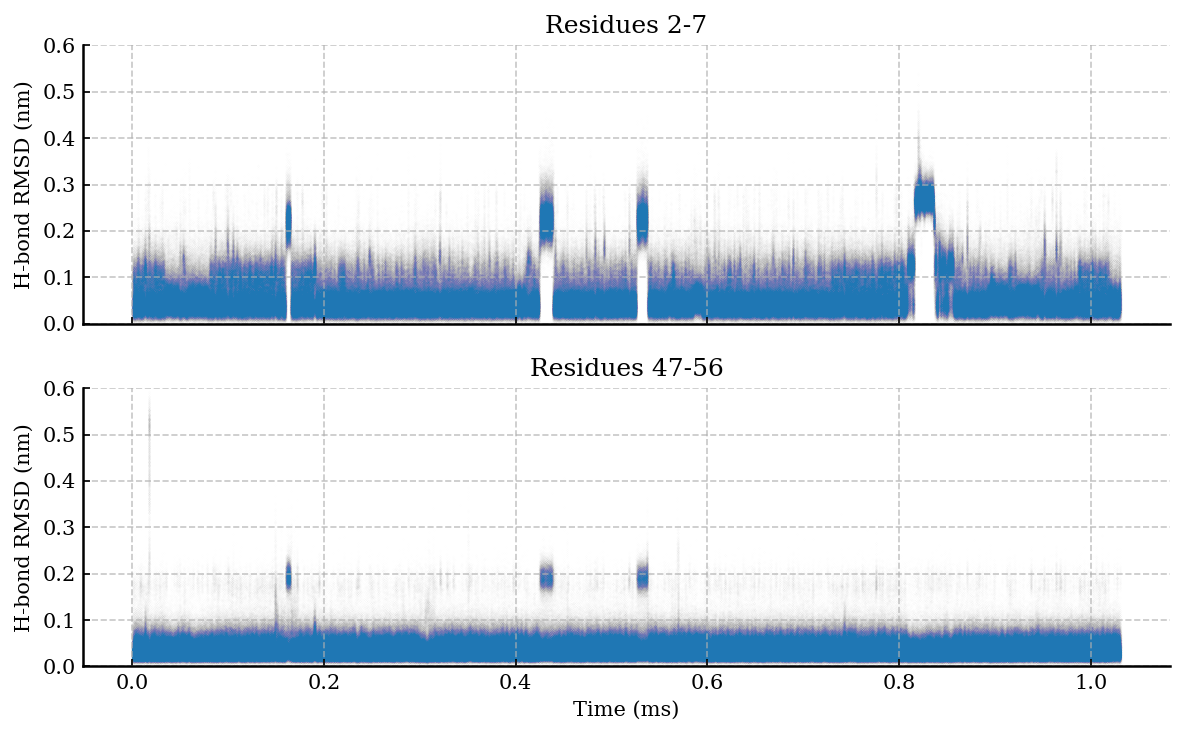

In [89]:
# plot H-bond RMSD time series for both BPTI helices

hbond_h1 = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_h2 = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res47_56_all_trajs.npy')

assert len(hbond_h1) == len(hbond_h2)

# each frame = 0.25 ns
time_ms = np.arange(len(hbond_h1)) * 0.25 / 1e6

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

axes[0].scatter(time_ms, hbond_h1, s=0.05, alpha=0.005, rasterized=True)
axes[1].scatter(time_ms, hbond_h2, s=0.05, alpha=0.005, rasterized=True)

axes[0].set_ylabel("H-bond RMSD (nm)")
axes[1].set_ylabel("H-bond RMSD (nm)")
axes[1].set_xlabel("Time (ms)")

axes[0].set_title("Residues 2-7")
axes[1].set_title("Residues 47-56")

for ax in axes:
    ax.set_ylim(0,0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", which="both", top=False)
    ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig("BPTI_helix_hbond_rmsd_timeseries.pdf", dpi=300)
plt.show()

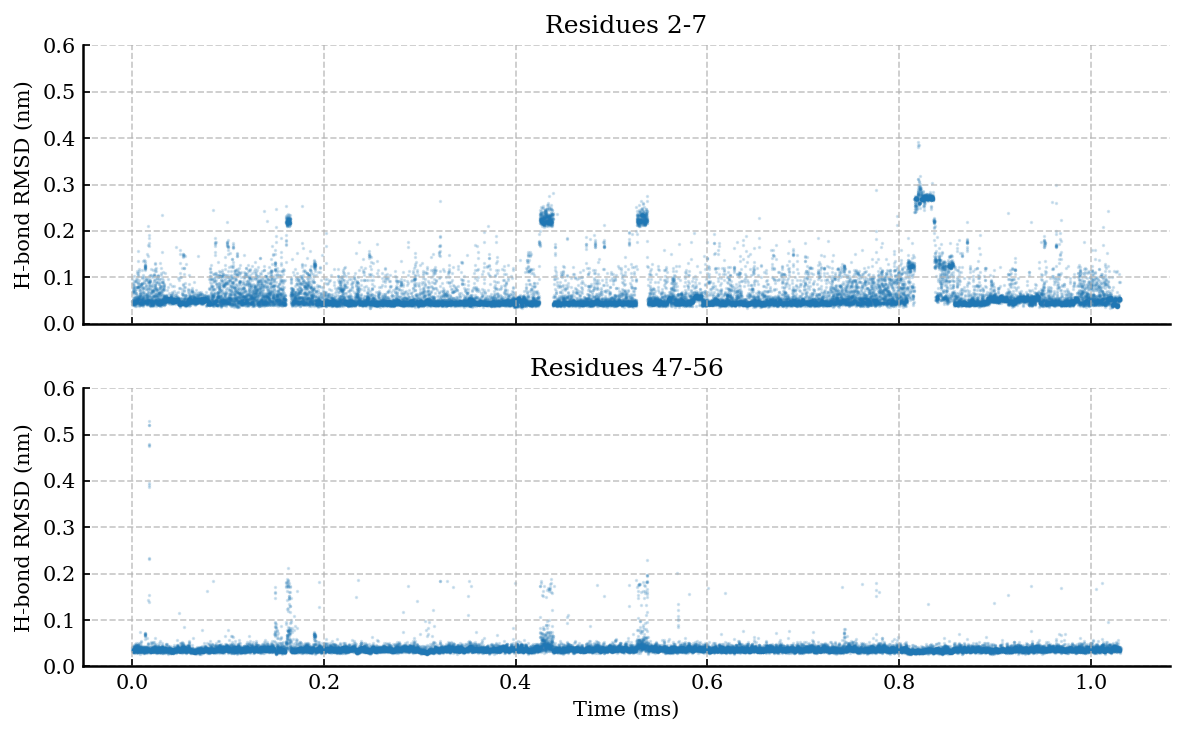

In [90]:
# plot 50 ns median H-bond RMSD time series for both BPTI helices

hbond_h1 = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_h2 = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res47_56_all_trajs.npy')

assert len(hbond_h1) == len(hbond_h2)

# each frame = 0.25 ns
dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

# trim to complete 50 ns blocks
nblocks = len(hbond_h1) // window_frames
nuse = nblocks * window_frames

hbond_h1_use = hbond_h1[:nuse]
hbond_h2_use = hbond_h2[:nuse]

# median within each 50 ns block
hbond_h1_median = np.median(hbond_h1_use.reshape(nblocks, window_frames), axis=1)
hbond_h2_median = np.median(hbond_h2_use.reshape(nblocks, window_frames), axis=1)

# time at center of each 50 ns block, converted to ms
time_ms = (np.arange(nblocks) + 0.5) * window_ns / 1e6

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

axes[0].scatter(time_ms, hbond_h1_median, s=0.4, alpha=0.2, rasterized=True)
axes[1].scatter(time_ms, hbond_h2_median, s=0.4, alpha=0.2, rasterized=True)

axes[0].set_ylabel("H-bond RMSD (nm)")
axes[1].set_ylabel("H-bond RMSD (nm)")
axes[1].set_xlabel("Time (ms)")

axes[0].set_title("Residues 2-7")
axes[1].set_title("Residues 47-56")

for ax in axes:
    ax.set_ylim(0, 0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", which="both", top=False)
    ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig("BPTI_helix_hbond_rmsd_timeseries_median_50ns.pdf", dpi=300)
plt.show()

In [91]:
# multiple excursions with helix 1 at least partially unfolded

Using posterior index 48, phi = 0.4972
Population in H1 RMSD 0.20-0.25 nm: 2.215%


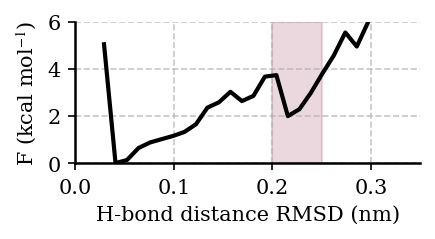

In [2]:
# 1D FEL along H-bond RMSD for BPTI residues 2-7
# using 50 ns median values and the posterior closest to phi = 0.5
# highlighting the region 0.20-0.26 nm and printing its population

nbins = 30
max_energy = 6.0
hbond_max = 0.35

dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

k = 0.008314
T = 300.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"
HIGHLIGHT_COLOR = "#BB8194"

# load H-bond distance RMSD
hbond_rms = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_rms = np.asarray(hbond_rms, dtype=float)

# load posterior weights and phi values
wopt_array = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# choose posterior closest to phi = 0.5
target_phi = 0.5
post_idx = np.argmin(np.abs(phi - target_phi))
w_post = np.asarray(wopt_array[post_idx], dtype=float)
w_post = w_post / np.sum(w_post)

print(f"Using posterior index {post_idx}, phi = {phi[post_idx]:.4f}")

# sanity check
assert len(hbond_rms) == len(w_post), f"hbond_rms and w_post must have the same length: {len(hbond_rms)}, {len(w_post)}"

# trim to complete 50 ns blocks
nblocks = len(hbond_rms) // window_frames
nuse = nblocks * window_frames

hbond_rms_use = hbond_rms[:nuse]
w_post_use = w_post[:nuse]

# 50 ns median values
hbond_rms_median = np.median(hbond_rms_use.reshape(nblocks, window_frames), axis=1)

# posterior block weights = sum of frame weights in each 50 ns block
w_post_block = np.sum(w_post_use.reshape(nblocks, window_frames), axis=1)
w_post_block = w_post_block / np.sum(w_post_block)

# population in highlighted region using the full posterior ensemble
state_mask = (hbond_rms_median >= 0.20) & (hbond_rms_median <= 0.25)
state_population = np.sum(w_post_block[state_mask])

print(f'Population in H1 RMSD 0.20-0.25 nm: {100 * state_population:.3f}%')

# restrict to plotting range
keep = np.isfinite(hbond_rms_median) & (hbond_rms_median >= 0.0) & (hbond_rms_median <= hbond_max)

hbond_plot = hbond_rms_median[keep]
w_plot = w_post_block[keep]

# renormalize weights within plotting range
w_plot = w_plot / np.sum(w_plot)

# histogram
bin_edges = np.linspace(0.0, hbond_max, nbins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts_post, _ = np.histogram(hbond_plot, bins=bin_edges, weights=w_plot)
p_post = counts_post / np.sum(counts_post)

# convert to FEL
fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0

fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.axvspan(0.20, 0.25, color=HIGHLIGHT_COLOR, alpha=0.3, zorder=0)
ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2, zorder=2)

ax.set_xlabel("H-bond distance RMSD (nm)")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

ax.set_xlim(0.0, hbond_max)
ax.set_ylim(0.0, max_energy)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig('posterior_phi05_fel_1D_hbond_rms_res2_7_50ns_median_highlighted.pdf', bbox_inches="tight")
plt.show()

Population in H1 RMSD 0.20-0.25 nm: 1.532%


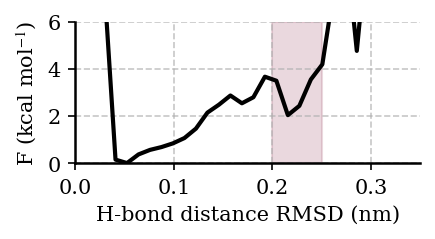

In [3]:
# 1D FEL along H-bond RMSD for BPTI residues 2-7
# using 50 ns median values and the posterior closest to phi = 0.5
# highlighting the region 0.20-0.26 nm and printing its population
# posterior 2

nbins = 30
max_energy = 6.0
hbond_max = 0.35

dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

k = 0.008314
T = 300.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"
HIGHLIGHT_COLOR = "#BB8194"

# load H-bond distance RMSD
hbond_rms = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_rms = np.asarray(hbond_rms, dtype=float)

# load posterior weights and phi values
w_post = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_wopt.npy') # posterior 2

# sanity check
assert len(hbond_rms) == len(w_post), f"hbond_rms and w_post must have the same length: {len(hbond_rms)}, {len(w_post)}"

# trim to complete 50 ns blocks
nblocks = len(hbond_rms) // window_frames
nuse = nblocks * window_frames

hbond_rms_use = hbond_rms[:nuse]
w_post_use = w_post[:nuse]

# 50 ns median values
hbond_rms_median = np.median(hbond_rms_use.reshape(nblocks, window_frames), axis=1)

# posterior block weights = sum of frame weights in each 50 ns block
w_post_block = np.sum(w_post_use.reshape(nblocks, window_frames), axis=1)
w_post_block = w_post_block / np.sum(w_post_block)

# population in highlighted region using the full posterior ensemble
state_mask = (hbond_rms_median >= 0.20) & (hbond_rms_median <= 0.25)
state_population = np.sum(w_post_block[state_mask])

print(f'Population in H1 RMSD 0.20-0.25 nm: {100 * state_population:.3f}%')

# restrict to plotting range
keep = np.isfinite(hbond_rms_median) & (hbond_rms_median >= 0.0) & (hbond_rms_median <= hbond_max)

hbond_plot = hbond_rms_median[keep]
w_plot = w_post_block[keep]

# renormalize weights within plotting range
w_plot = w_plot / np.sum(w_plot)

# histogram
bin_edges = np.linspace(0.0, hbond_max, nbins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts_post, _ = np.histogram(hbond_plot, bins=bin_edges, weights=w_plot)
p_post = counts_post / np.sum(counts_post)

# convert to FEL
fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0

fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.axvspan(0.20, 0.25, color=HIGHLIGHT_COLOR, alpha=0.3, zorder=0)
ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2, zorder=2)

ax.set_xlabel("H-bond distance RMSD (nm)")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

ax.set_xlim(0.0, hbond_max)
ax.set_ylim(0.0, max_energy)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig('posterior2_fel_1D_hbond_rms_res2_7_50ns_median_highlighted.pdf', bbox_inches="tight")
plt.show()

In [93]:
# ------------------------------------------------------------
# Save top 10 representative structures from H1 RMSD 0.20-0.25 nm
# using 50 ns median windows
# rank first by distance from posterior FEL minimum,
# then by posterior block weight (highest first)
# ------------------------------------------------------------

import os
import mdtraj as md

state_low = 0.20
state_high = 0.25
n_structures = 10

dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

nbins = 30
hbond_max = 0.35

traj_dir = '../../DESRES_NATIVE_DATA/BPTI/'
topology_file = '../../DESRES_NATIVE_DATA/BPTI/protein.pdb'

outdir = 'BPTI_H1_state_020_025_top10'
os.makedirs(outdir, exist_ok=True)

# trajectories in exactly the same order used for the H-bond RMSD calculation
trajs = sorted(find_xtc_filenames(traj_dir))

# load H1 H-bond RMSD
hbond_rms = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_rms = np.asarray(hbond_rms, dtype=float)

# load posterior weights and phi values
wopt_array = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior closest to phi = 0.5
target_phi = 0.5
post_idx = np.argmin(np.abs(phi - target_phi))
w_post = np.asarray(wopt_array[post_idx], dtype=float)
w_post /= np.sum(w_post)

print(f'Using posterior index {post_idx}, phi = {phi[post_idx]:.4f}')

assert len(hbond_rms) == len(w_post), f'hbond_rms and w_post must have same length: {len(hbond_rms)}, {len(w_post)}'

# ------------------------------------------------------------
# 50 ns median blocks
# ------------------------------------------------------------

nblocks = len(hbond_rms) // window_frames
nuse = nblocks * window_frames

hbond_rms_use = hbond_rms[:nuse]
w_post_use = w_post[:nuse]

hbond_blocks = hbond_rms_use.reshape(nblocks, window_frames)
weight_blocks = w_post_use.reshape(nblocks, window_frames)

# median H1 RMSD in each 50 ns block
hbond_median = np.median(hbond_blocks, axis=1)

# posterior probability mass of each 50 ns block
w_block = np.sum(weight_blocks, axis=1)
w_block /= np.sum(w_block)

# ------------------------------------------------------------
# Calculate posterior 1D FEL from 50 ns medians
# ------------------------------------------------------------

bin_edges = np.linspace(0.0, hbond_max, nbins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts, _ = np.histogram(hbond_median, bins=bin_edges, weights=w_block)
p = counts / np.sum(counts)

fel = np.full_like(p, np.nan, dtype=float)
valid = p > 0
fel[valid] = -np.log(p[valid])
fel -= np.nanmin(fel)

# ------------------------------------------------------------
# Find FEL minimum within 0.20-0.25 nm
# ------------------------------------------------------------

state_bins = (bin_centers >= state_low) & (bin_centers <= state_high) & np.isfinite(fel)

if not np.any(state_bins):
    raise RuntimeError('No populated FEL bins found in the 0.20-0.25 nm region')

state_bin_indices = np.where(state_bins)[0]
min_bin = state_bin_indices[np.argmin(fel[state_bins])]
state_center = bin_centers[min_bin]

print(f'Posterior FEL minimum in 0.20-0.25 nm region: {state_center:.4f} nm')

# ------------------------------------------------------------
# Select candidate 50 ns blocks
# ------------------------------------------------------------

candidate_blocks = np.where((hbond_median >= state_low) & (hbond_median <= state_high))[0]

if len(candidate_blocks) == 0:
    raise RuntimeError('No 50 ns blocks have median H1 RMSD in 0.20-0.25 nm')

distance_from_min = np.abs(hbond_median[candidate_blocks] - state_center)

# primary sort: distance from FEL minimum
# secondary sort: posterior block weight, highest first
order = np.lexsort((-w_block[candidate_blocks], distance_from_min))
selected_blocks = candidate_blocks[order[:n_structures]]

print('\nSelected 50 ns blocks:')
print('rank   block   median_RMSD   distance   posterior_weight')

for rank, block in enumerate(selected_blocks, start=1):
    print(f'{rank:4d}   {block:5d}   {hbond_median[block]:11.4f}   {abs(hbond_median[block] - state_center):8.4f}   {w_block[block]:.8e}')

# ------------------------------------------------------------
# Determine trajectory lengths for global-frame mapping
# ------------------------------------------------------------

traj_lengths = []

for traj_file in trajs:
    traj_path = os.path.join(traj_dir, traj_file)

    with md.open(traj_path) as f:
        traj_lengths.append(len(f))

traj_lengths = np.asarray(traj_lengths, dtype=int)

traj_starts = np.concatenate(([0], np.cumsum(traj_lengths)[:-1]))
traj_ends = np.cumsum(traj_lengths)

assert np.sum(traj_lengths) >= nuse, f'Trajectories contain {np.sum(traj_lengths)} frames but H-bond array uses {nuse}'

# ------------------------------------------------------------
# Save representative structure from each selected block
# ------------------------------------------------------------

metadata = []

for rank, block in enumerate(selected_blocks, start=1):

    block_start = block * window_frames
    block_end = block_start + window_frames

    # choose actual frame within the 50 ns block whose H1 RMSD
    # is closest to the block median
    block_values = hbond_rms_use[block_start:block_end]
    local_block_idx = np.argmin(np.abs(block_values - hbond_median[block]))
    global_frame = block_start + local_block_idx

    # map global frame onto trajectory + local frame
    traj_idx = np.searchsorted(traj_ends, global_frame, side='right')
    frame_idx = global_frame - traj_starts[traj_idx]

    traj_file = trajs[traj_idx]
    traj_path = os.path.join(traj_dir, traj_file)

    # load representative frame
    structure = md.load_frame(traj_path, index=int(frame_idx), top=topology_file)

    outfile = os.path.join(outdir, f'BPTI_H1_state_020_025_rank{rank:02d}.pdb')
    structure.save_pdb(outfile)

    distance = abs(hbond_median[block] - state_center)

    metadata.append([
        rank,
        block,
        hbond_median[block],
        distance,
        w_block[block],
        global_frame,
        traj_idx,
        frame_idx
    ])

    print(
        f'{outfile}: '
        f'block={block}, '
        f'median={hbond_median[block]:.4f} nm, '
        f'distance={distance:.4f} nm, '
        f'weight={w_block[block]:.8e}, '
        f'traj={traj_file}, '
        f'frame={frame_idx}'
    )

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------

metadata = np.asarray(metadata)

np.savetxt(
    os.path.join(outdir, 'representative_structures.dat'),
    metadata,
    header='rank block median_H1_RMSD_nm distance_from_min_nm posterior_block_weight global_frame traj_index frame_index',
    fmt=['%d', '%d', '%.6f', '%.6f', '%.10e', '%d', '%d', '%d']
)

Using posterior index 48, phi = 0.4972
Posterior FEL minimum in 0.20-0.25 nm region: 0.2158 nm

Selected 50 ns blocks:
rank   block   median_RMSD   distance   posterior_weight
   1   10630        0.2158     0.0000   4.24767508e-05
   2    8748        0.2158     0.0000   2.37525183e-05
   3    8562        0.2159     0.0000   3.63825085e-05
   4    8687        0.2159     0.0000   3.60788288e-05
   5   10695        0.2158     0.0000   4.36116778e-05
   6    3220        0.2158     0.0001   1.24878567e-04
   7    8538        0.2160     0.0001   3.12215593e-05
   8    8716        0.2157     0.0001   3.57139068e-05
   9   10705        0.2157     0.0001   3.91466517e-05
  10   10580        0.2160     0.0001   4.13191152e-05
BPTI_H1_state_020_025_top10/BPTI_H1_state_020_025_rank01.pdb: block=10630, median=0.2158 nm, distance=0.0000 nm, weight=4.24767508e-05, traj=bpti-protein-212.xtc, frame=6114
BPTI_H1_state_020_025_top10/BPTI_H1_state_020_025_rank02.pdb: block=8748, median=0.2158 nm, distance

Prior population in H1 RMSD 0.20-0.25 nm: 3.016%


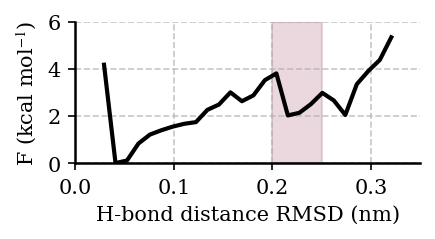

In [99]:
# 1D FEL along H-bond RMSD for BPTI residues 2-7
# using 50 ns median values for the PRIOR ensemble only
# highlighting the region 0.20-0.26 nm and printing its population

nbins = 30
max_energy = 6.0
hbond_max = 0.35

dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

k = 0.008314
T = 300.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_PRIOR = "black"
HIGHLIGHT_COLOR = "#BB8194"

# load H-bond distance RMSD
hbond_rms = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_rms = np.asarray(hbond_rms, dtype=float)

# trim to complete 50 ns blocks
nblocks = len(hbond_rms) // window_frames
nuse = nblocks * window_frames

hbond_rms_use = hbond_rms[:nuse]

# 50 ns median values
hbond_rms_median = np.median(hbond_rms_use.reshape(nblocks, window_frames), axis=1)

# prior: each 50 ns block has equal weight
w_prior_block = np.ones(nblocks, dtype=float)
w_prior_block = w_prior_block / np.sum(w_prior_block)

# population in highlighted region
state_mask = (hbond_rms_median >= 0.20) & (hbond_rms_median <= 0.25)
state_population_prior = np.sum(w_prior_block[state_mask])

print(f'Prior population in H1 RMSD 0.20-0.25 nm: {100 * state_population_prior:.3f}%')

# restrict to plotting range
keep = np.isfinite(hbond_rms_median) & (hbond_rms_median >= 0.0) & (hbond_rms_median <= hbond_max)

hbond_plot = hbond_rms_median[keep]
w_plot = w_prior_block[keep]

# renormalize weights within plotting range
w_plot = w_plot / np.sum(w_plot)

# histogram
bin_edges = np.linspace(0.0, hbond_max, nbins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts_prior, _ = np.histogram(hbond_plot, bins=bin_edges, weights=w_plot)
p_prior = counts_prior / np.sum(counts_prior)

# convert to FEL
fel_prior = np.full_like(p_prior, np.nan, dtype=float)
valid = p_prior > 0

fel_prior[valid] = -np.log(p_prior[valid]) * kT
fel_prior = (fel_prior - np.nanmin(fel_prior)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.axvspan(0.20, 0.25, color=HIGHLIGHT_COLOR, alpha=0.3, zorder=0)
ax.plot(bin_centers, fel_prior, color=COLOR_PRIOR, lw=2, zorder=2)

ax.set_xlabel("H-bond distance RMSD (nm)")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

ax.set_xlim(0.0, hbond_max)
ax.set_ylim(0.0, max_energy)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig('prior_fel_1D_hbond_rms_res2_7_50ns_median_highlighted.pdf', bbox_inches="tight")
plt.show()

Prior population in H1 RMSD 0.25-0.30 nm: 1.959%


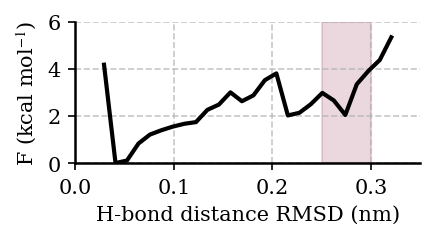

In [100]:
# 1D FEL along H-bond RMSD for BPTI residues 2-7
# using 50 ns median values for the PRIOR ensemble only
# highlighting the region 0.25-0.30 nm and printing its population

nbins = 30
max_energy = 6.0
hbond_max = 0.35

dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

k = 0.008314
T = 300.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_PRIOR = "black"
HIGHLIGHT_COLOR = "#BB8194"

# load H-bond distance RMSD
hbond_rms = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_rms = np.asarray(hbond_rms, dtype=float)

# trim to complete 50 ns blocks
nblocks = len(hbond_rms) // window_frames
nuse = nblocks * window_frames

hbond_rms_use = hbond_rms[:nuse]

# 50 ns median values
hbond_rms_median = np.median(hbond_rms_use.reshape(nblocks, window_frames), axis=1)

# prior: each 50 ns block has equal weight
w_prior_block = np.ones(nblocks, dtype=float)
w_prior_block = w_prior_block / np.sum(w_prior_block)

# population in highlighted region
state_mask = (hbond_rms_median >= 0.25) & (hbond_rms_median <= 0.30)
state_population_prior = np.sum(w_prior_block[state_mask])

print(f'Prior population in H1 RMSD 0.25-0.30 nm: {100 * state_population_prior:.3f}%')

# restrict to plotting range
keep = np.isfinite(hbond_rms_median) & (hbond_rms_median >= 0.0) & (hbond_rms_median <= hbond_max)

hbond_plot = hbond_rms_median[keep]
w_plot = w_prior_block[keep]

# renormalize weights within plotting range
w_plot = w_plot / np.sum(w_plot)

# histogram
bin_edges = np.linspace(0.0, hbond_max, nbins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts_prior, _ = np.histogram(hbond_plot, bins=bin_edges, weights=w_plot)
p_prior = counts_prior / np.sum(counts_prior)

# convert to FEL
fel_prior = np.full_like(p_prior, np.nan, dtype=float)
valid = p_prior > 0

fel_prior[valid] = -np.log(p_prior[valid]) * kT
fel_prior = (fel_prior - np.nanmin(fel_prior)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.axvspan(0.25, 0.30, color=HIGHLIGHT_COLOR, alpha=0.3, zorder=0)
ax.plot(bin_centers, fel_prior, color=COLOR_PRIOR, lw=2, zorder=2)

ax.set_xlabel("H-bond distance RMSD (nm)")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

ax.set_xlim(0.0, hbond_max)
ax.set_ylim(0.0, max_energy)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig('prior_fel_1D_hbond_rms_res2_7_50ns_median_highlighted_025_030.pdf', bbox_inches="tight")
plt.show()

In [96]:
# posterior population in the 0.25-0.30 nm region using 50 ns median values

dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

hbond_rms = np.load('../../DESRES_NATIVE_DATA/BPTI/hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_rms = np.asarray(hbond_rms, dtype=float)

wopt_array = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

target_phi = 0.5
post_idx = np.argmin(np.abs(phi - target_phi))
w_post = np.asarray(wopt_array[post_idx], dtype=float)
w_post = w_post / np.sum(w_post)

nblocks = len(hbond_rms) // window_frames
nuse = nblocks * window_frames

hbond_rms_median = np.median(hbond_rms[:nuse].reshape(nblocks, window_frames), axis=1)

w_post_block = np.sum(w_post[:nuse].reshape(nblocks, window_frames), axis=1)
w_post_block = w_post_block / np.sum(w_post_block)

state_mask = (hbond_rms_median >= 0.25) & (hbond_rms_median <= 0.30)
state_population_post = np.sum(w_post_block[state_mask])

print(f'Posterior population in H1 RMSD 0.25-0.30 nm: {100 * state_population_post:.3f}%')

Posterior population in H1 RMSD 0.25-0.30 nm: 0.054%


Using posterior index 48, phi = 0.4972
Excited-state 50 ns blocks: 622 / 20624
Excited-state frames: 124400
Native-state frames: 2279705
Excited-state posterior population: 0.0222
Native-state posterior population: 0.6285


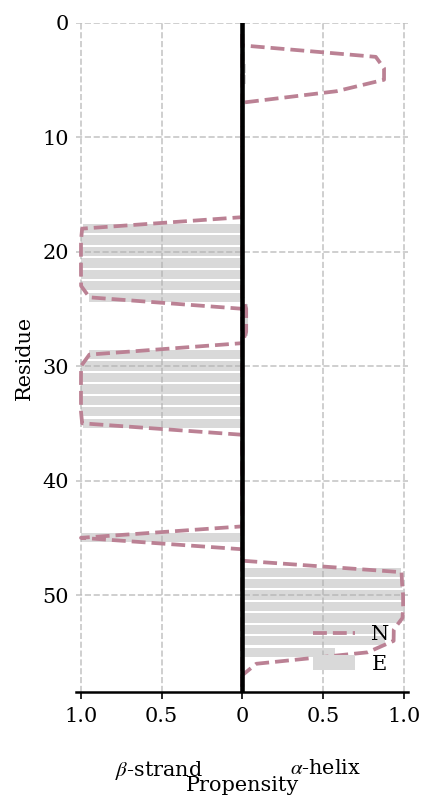

In [97]:
# secondary-structure propensity of H1 excited state
#
# Native ground state:
#   BB RMSD = 0.12-0.16 nm
#
# Excited state:
#   50 ns median H1 H-bond RMSD = 0.20-0.25 nm

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# Function to calculate per-residue helicity per frame
def dssp_to_strand(dssp_lines):
    """
    same thing for beta strand
    """
    strand_codes = {'E', 'B'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    strandicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        strandicity[i, :] = [1 if c in strand_codes else 0 for c in line]
    
    return strandicity

path = '../../DESRES_NATIVE_DATA/BPTI/'

dt_ns = 0.25
window_ns = 50.0
window_frames = int(window_ns / dt_ns)

# ------------------------------------------------------------
# Load DSSP
# ------------------------------------------------------------

dssp = np.load(path + 'dssp_all_trajs.npy')

helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

# ------------------------------------------------------------
# Load H1 H-bond RMSD
# ------------------------------------------------------------

hbond_h1 = np.load(path + 'hbond_distance_rmsd_res2_7_all_trajs.npy')
hbond_h1 = np.asarray(hbond_h1, dtype=float)

# ------------------------------------------------------------
# Load backbone RMSD
# ------------------------------------------------------------

rmsd = []

for traj in trajs:
    tmp = np.loadtxt(path + f'rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
    rmsd.append(tmp)

rmsd = np.concatenate(rmsd)

# ------------------------------------------------------------
# Load posterior closest to phi = 0.5
# ------------------------------------------------------------

wopt_array = np.load(path + 'rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(path + 'rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

target_phi = 0.5
post_idx = np.argmin(np.abs(phi - target_phi))

wopt = np.asarray(wopt_array[post_idx], dtype=float)
wopt = wopt / np.sum(wopt)

print(f'Using posterior index {post_idx}, phi = {phi[post_idx]:.4f}')

# sanity check
assert len(hbond_h1) == len(rmsd) == len(dssp) == len(wopt), f'Length mismatch: hbond={len(hbond_h1)}, rmsd={len(rmsd)}, dssp={len(dssp)}, wopt={len(wopt)}'

# ------------------------------------------------------------
# Calculate 50 ns median H1 H-bond RMSD
# ------------------------------------------------------------

nblocks = len(hbond_h1) // window_frames
nuse = nblocks * window_frames

hbond_h1_use = hbond_h1[:nuse]

hbond_h1_blocks = hbond_h1_use.reshape(nblocks, window_frames)
hbond_h1_median = np.median(hbond_h1_blocks, axis=1)

# excited-state 50 ns windows
mask_E_blocks = (hbond_h1_median >= 0.20) & (hbond_h1_median <= 0.25)

# convert block-level definition back to frame-level mask
mask_E = np.zeros(len(hbond_h1), dtype=bool)
mask_E[:nuse] = np.repeat(mask_E_blocks, window_frames)

# ------------------------------------------------------------
# Native ground state from backbone RMSD
# ------------------------------------------------------------

mask_N = (rmsd >= 0.12) & (rmsd <= 0.16)

# ------------------------------------------------------------
# Print populations
# ------------------------------------------------------------

print(f'Excited-state 50 ns blocks: {np.sum(mask_E_blocks)} / {nblocks}')
print(f'Excited-state frames: {np.sum(mask_E)}')
print(f'Native-state frames: {np.sum(mask_N)}')

print(f'Excited-state posterior population: {np.sum(wopt[mask_E]):.4f}')
print(f'Native-state posterior population: {np.sum(wopt[mask_N]):.4f}')

# ------------------------------------------------------------
# Weighted secondary-structure propensities
# ------------------------------------------------------------

alpha_E = np.average(helicity[mask_E], axis=0, weights=wopt[mask_E])
beta_E = np.average(strand[mask_E], axis=0, weights=wopt[mask_E])

alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(3.0, 5.5))

# excited state as bars
ax.barh(residues, -beta_E, height=0.8, color="#D9D9D9", edgecolor="none", label="E")
ax.barh(residues, alpha_E, height=0.8, color="#D9D9D9", edgecolor="none")

# native ground state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# axis labels
ax.set_ylabel("Residue")
ax.set_xlabel("Propensity", labelpad=24)

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# secondary-structure labels
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks
yticks = np.arange(0, len(residues) + 1, 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig('BPTI_H1_excited_020_025_50ns_median_SS.pdf', bbox_inches="tight")
plt.show()